# Experiment 2: recovery after content perturbations

This notebook tests whether the originally designated content remains recoverable when it also changes across augmented views. It adapts the four Gaussian simulation settings of [von Kügelgen et al. (2021)](https://arxiv.org/abs/2106.04619): independent factors with style-selection probability $p=1$ or $0.75$, correlated latent blocks with $p=0.75$, and content-dependent style with $p=0.75$.

The main comparison has five encoder outputs, content perturbation strengths $\sigma_c\in\{0,0.1\}$, three seeds and 10,000 updates per run: 24 completed runs. Each seed determines the world parameters, mixing network, encoder initialization, training stream and probe samples. The invariant and perturbed conditions are paired within each seed. Training uses 1,024 positive pairs and 1,024 independent negatives per update; the budget and evaluation sample sizes differ from the paper's full experiment.

The saved paired table supplies the report's Experiment 2 results. A separate independent-setting strength sweep uses seed 0; its five strengths reuse two main-comparison runs and add three, giving 27 unique runs at the defaults. Earlier unpaired summaries are retained in the historical appendix.

Tables and figures are already embedded. To reproduce them, run the notebook in order; compatible completed-run caches are reused when available. Fresh execution without those caches trains the models. Use persistent storage for the result directory when running in Colab.


## Part A: shared simulation setup

These cells define the Gaussian reference model, latent augmentation, fixed mixing network, encoder, and contrastive loss. The implementation is adapted from the synthetic experiments in [von Kügelgen et al. (2021)](https://arxiv.org/abs/2106.04619) and their [released code](https://github.com/ysharma1126/ssl_identifiability/tree/ee46a35acf68461172b3eaeeb1d6fbc779fce661). Part B specifies the distributions, augmentation rules, output dimensions, and training budgets used in this notebook.

The notebook is self-contained. Run the setup before executing Part B; the saved tables and figures can be read without rerunning training.


### Environment and settings

The code uses Python, PyTorch, NumPy, SciPy, pandas, Matplotlib, and scikit-learn. The next cell records the software versions used for the saved execution. Dependencies are listed in the repository's `requirements.txt`. The device setting selects CUDA, then Apple MPS, then CPU when available; rerun results can vary across devices and software versions.


In [1]:
import copy
import math
import platform
import time
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import wishart
import sklearn
from sklearn.linear_model import LinearRegression
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

import torch
from torch import nn
from IPython.display import display

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelsize": 11, "axes.titlesize": 12, "font.size": 10,
})

versions = {
    "Python": platform.python_version(), "PyTorch": torch.__version__,
    "NumPy": np.__version__, "SciPy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
display(pd.Series(versions, name="Version").to_frame())

,Version
Python,3.13.15
PyTorch,2.11.0+cu130
NumPy,2.1.3
SciPy,1.16.3
scikit-learn,1.6.1


### Reference scenarios

The four scenarios follow the synthetic comparisons in Section 5.1 of [von Kügelgen et al. (2021)](https://arxiv.org/abs/2106.04619).

| Scenario | Style-coordinate selection probability | Dependence within blocks | Style depends on content |
| --- | ---: | --- | --- |
| `independent_all` | 1.00 | No | No |
| `independent_partial` | 0.75 | No | No |
| `dependent_blocks` | 0.75 | Yes | No |
| `content_causes_style` | 0.75 | Yes | Yes |

The reference model has five content factors and five style factors. `representation_dim` sets the number of encoder outputs, independently of those latent dimensions. Each update uses fresh simulated data; `batch_size` sets both the number of positive pairs and the size of the independent negative pool. The experiment cells below override the reference settings as needed.


In [2]:
SCENARIO = "independent_partial"

SCENARIOS = {
    "independent_all":      (1.00, False, False),
    "independent_partial":  (0.75, False, False),
    "dependent_blocks":     (0.75, True,  False),
    "content_causes_style": (0.75, True,  True),
}

@dataclass
class Settings:
    seed: int = 7                          # Controls randomness so a run can be repeated.
    content_dim: int = 5                   # Number of true content variables, unchanged across paired views.
    style_dim: int = 5                     # Number of true style variables, which may change across views.
    representation_dim: int = 5            # Number of encoder outputs; equals content_dim.
    style_change_prob: float = 0.75        # Probability that each style coordinate is selected for change ("Biased Coin")
    statistical_dependence: bool = False   # If True, allow correlations within content, style noise, and augmentation noise.
    content_dependent_style: bool = False  # If True, generate style as s = a + Bc + noise.
    marginal_std: float = 1.0              # Standard deviation of content and residual style noise when dependence is off.
    style_noise_std: float = 1.0           # Standard deviation of noise added to selected style coordinates when dependence is off.
    mixing_layers: int = 3                 # Number of linear layers in the fixed latent-to-observation network.
    condition_pool: int = 25000            # Number of random matrices used to estimate a conditioning threshold.
    condition_quantile: float = 0.001      # Set the threshold using roughly the best-conditioned 0.1% of those matrices.
    learning_rate: float = 1e-4            # Controls the size of the encoder's parameter updates during training.
    temperature: float = 1.0               # Scales distances in the contrastive loss; smaller values sharpen comparisons.
    batch_size: int = 1024                  # Positive pairs per update; also the number of independent negative examples.
    steps: int = 10000                      # Total number of encoder parameter updates.
    log_every: int = 200                   # Print training progress every this many updates.
    probe_train_size: int = 3000            # Examples used to fit evaluation models that predict latents from representations.
    probe_test_size: int = 5000            # Separate examples used to test those evaluation models.
    device: str = "auto"                   # Automatically choose CUDA, then MPS, then CPU; can also set one explicitly.

cfg = Settings()
(cfg.style_change_prob, cfg.statistical_dependence,
 cfg.content_dependent_style) = SCENARIOS[SCENARIO]

# Original script's training scale (not enabled for this demonstration):
# cfg.batch_size = 6144
# cfg.steps = 100001
# The original nonlinear evaluation fits probes on 5 * 4096 examples and
# evaluates on 10 fresh batches of 4096. Kernel regression at that size is costly.

assert min(cfg.content_dim, cfg.style_dim, cfg.representation_dim) >= 1
assert 0 <= cfg.style_change_prob <= 1
assert min(cfg.marginal_std, cfg.style_noise_std, cfg.temperature) > 0
assert cfg.steps > 0 and cfg.batch_size > 1

if cfg.device != "auto":
    device = torch.device(cfg.device)
elif torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

torch.manual_seed(cfg.seed)
torch.set_num_threads(2)  # Avoid oversubscribing CPU cores in small examples.
latent_dim = cfg.content_dim + cfg.style_dim
print(f"Scenario: {SCENARIO}; device: {device}")
display(pd.Series(asdict(cfg), name="Setting").to_frame())

Scenario: independent_partial; device: cuda


,Setting
seed,7
content_dim,5
style_dim,5
representation_dim,5
style_change_prob,0.75
statistical_dependence,False
content_dependent_style,False
marginal_std,1.0
style_noise_std,1.0
mixing_layers,3


### Gaussian reference model

The reference sampler draws

$$
c\sim N(0,\Sigma_c),\qquad
s=a+Bc+\varepsilon_s,\qquad
\varepsilon_s\sim N(0,\Sigma_s),
$$

with independent draws of $c$ and $\varepsilon_s$. In the independent scenarios, the covariance matrices are scalar multiples of the identity. In the dependent scenarios, Wishart draws provide positive definite covariance matrices and replace the scalar variance settings. Setting `content_dependent_style=True` introduces the term $a+Bc$; otherwise $a=B=0$.

The world parameters are fixed within a run. Repeated samples therefore come from the same data-generating distribution. Experiment-specific samplers are defined in Part B.


In [3]:
def make_world(settings):
    """Create fixed parameters of the data distribution on the CPU."""
    rng = np.random.default_rng(settings.seed)
    nc, ns = settings.content_dim, settings.style_dim

    def covariance(dim, std):
        if settings.statistical_dependence:
            # Match the intended Wishart construction in the original experiment.
            matrix = np.atleast_2d(wishart.rvs(df=dim, scale=np.eye(dim), random_state=rng))
        else:
            matrix = (std ** 2) * np.eye(dim)
        return torch.tensor(matrix, dtype=torch.float64)

    Sigma_c = covariance(nc, settings.marginal_std)
    Sigma_s = covariance(ns, settings.marginal_std)
    Sigma_aug = covariance(ns, settings.style_noise_std)
    # As in upstream spaces.py, explicit covariances supersede the std arguments.
    a = torch.zeros(ns)
    B = torch.zeros(ns, nc)
    if settings.content_dependent_style:
        a = torch.tensor(rng.standard_normal(ns), dtype=torch.float32)
        B = torch.tensor(rng.standard_normal((ns, nc)), dtype=torch.float32)
    return {
        "L_c": torch.linalg.cholesky(Sigma_c).float(),
        "L_s": torch.linalg.cholesky(Sigma_s).float(),
        "L_aug": torch.linalg.cholesky(Sigma_aug).float(),
        "a": a, "B": B,
    }

world = make_world(cfg)

def sample_latents(size, generator):
    """Draw z=(c,s). Latent values are used by the simulator and evaluator."""
    c = torch.randn(size, cfg.content_dim, generator=generator) @ world["L_c"].T
    eps_s = torch.randn(size, cfg.style_dim, generator=generator) @ world["L_s"].T
    s = world["a"] + c @ world["B"].T + eps_s
    return torch.cat([c, s], dim=1)

display(pd.DataFrame({
    "block": ["content", "style residual", "augmentation noise"],
    "dimension": [cfg.content_dim, cfg.style_dim, cfg.style_dim],
    "covariance": ["L_c @ L_c.T", "L_s @ L_s.T", "L_aug @ L_aug.T"],
}))

,block,dimension,covariance
0,content,5,L_c @ L_c.T
1,style residual,5,L_s @ L_s.T
2,augmentation noise,5,L_aug @ L_aug.T


### Reference augmentation and negative samples

The reference augmentation copies content and adds masked Gaussian noise to style:

$$
M_j\sim\operatorname{Bernoulli}(p),\qquad
\tilde s=s+M\odot\eta,\qquad
\eta\sim N(0,\Sigma_{\mathrm{aug}}).
$$

The mask entries are independent, and the mask and noise are independent of the original latents. The operator $\odot$ denotes coordinatewise multiplication. When $p>0$ and $\Sigma_{\mathrm{aug}}$ is positive definite, every style coordinate can vary locally. The negative samples are independent draws from the original latent distribution. Part B defines any changes to this reference augmentation.


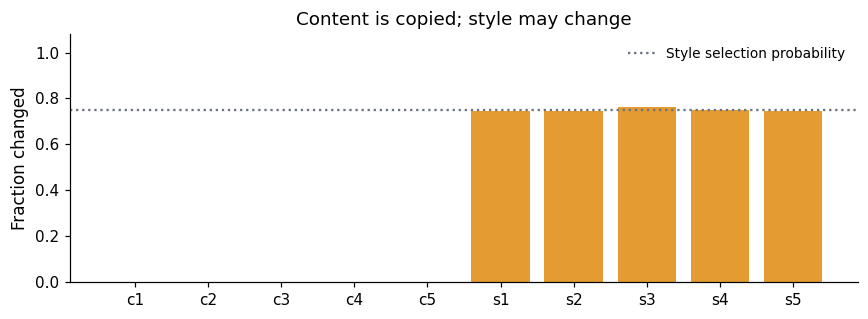

In [4]:
def augment_latents(z, generator):
    nc = cfg.content_dim
    style = z[:, nc:]
    mask = (torch.rand(style.shape, generator=generator) < cfg.style_change_prob)
    noise = torch.randn(style.shape, generator=generator) @ world["L_aug"].T
    changed_style = style + mask * noise
    return torch.cat([z[:, :nc], changed_style], dim=1)

def sample_triplet(size, generator):
    z = sample_latents(size, generator)
    z_negative = sample_latents(size, generator)
    z_augmented = augment_latents(z, generator)
    return z, z_augmented, z_negative

# A separate random stream keeps this inspection from changing training data.
inspection_rng = torch.Generator().manual_seed(cfg.seed + 10)
z_check, z_aug_check, _ = sample_triplet(5000, inspection_rng)
assert torch.equal(z_check[:, :cfg.content_dim], z_aug_check[:, :cfg.content_dim])
change_rates = (z_check != z_aug_check).float().mean(dim=0).numpy()
names = ([f"c{i+1}" for i in range(cfg.content_dim)] +
         [f"s{i+1}" for i in range(cfg.style_dim)])

fig, ax = plt.subplots(figsize=(8, 3))
colors = ["#227c9d"] * cfg.content_dim + ["#e49b32"] * cfg.style_dim
ax.bar(names, change_rates, color=colors)
ax.axhline(cfg.style_change_prob, color="#6b7280", linestyle=":", label="Style selection probability")
ax.set(ylim=(0, 1.08), ylabel="Fraction changed", title="Content is copied; style may change")
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

### Fixed mixing network

The mixing network maps $z=(c,s)$ to $x=f(z)$. Its square nonsingular weight matrices and LeakyReLU activations with nonzero negative slope make the map invertible. The code selects well-conditioned matrices to limit numerical distortion, then freezes the mixing network during encoder training.

LeakyReLU has a kink at zero, so this implementation is not smooth everywhere as required by the paper's theoretical model.


In [5]:
def make_mixing(settings):
    """Adapt the upstream well-conditioned, square mixing MLP."""
    n = settings.content_dim + settings.style_dim
    rng = np.random.default_rng(settings.seed + 100)

    def candidate():
        matrix = rng.uniform(-1, 1, size=(n, n))
        return matrix / np.linalg.norm(matrix, axis=0, keepdims=True)

    conditions = np.array([
        np.linalg.cond(candidate()) for _ in range(settings.condition_pool)
    ])
    threshold = np.sort(conditions)[int(settings.condition_pool * settings.condition_quantile)]
    modules, accepted_conditions = [], []
    for layer in range(settings.mixing_layers):
        matrix = candidate()
        while np.linalg.cond(matrix) > threshold:
            matrix = candidate()
        linear = nn.Linear(n, n, bias=False)
        with torch.no_grad():
            linear.weight.copy_(torch.tensor(matrix, dtype=torch.float32))
        modules.append(linear)
        accepted_conditions.append(np.linalg.cond(matrix))
        if layer < settings.mixing_layers - 1:
            modules.append(nn.LeakyReLU(negative_slope=0.2))
    network = nn.Sequential(*modules).to(device)
    network.requires_grad_(False)
    network.eval()
    return network, accepted_conditions

mixing, condition_numbers = make_mixing(cfg)
print("Mixing layer condition numbers:", np.round(condition_numbers, 2))
print("Mixing parameters trainable:", any(p.requires_grad for p in mixing.parameters()))

with torch.no_grad():
    x_check = mixing(z_check[:5].to(device))
print("Latent shape:", tuple(z_check[:5].shape))
print("Observation shape:", tuple(x_check.shape))

Mixing layer condition numbers: [4.56 4.26 4.91]
Mixing parameters trainable: False
Latent shape: (5, 10)
Observation shape: (5, 10)


### Encoder

The base encoder uses the hidden-layer widths and LeakyReLU activations of the released `main_mlp.py`, with an unbounded final linear layer. Its output dimension is $d=\texttt{representation_dim}$. The learned composite map is $h=g\circ f$, from the ten latent coordinates to $d$ representation coordinates. Part B specifies the output dimension and any additional output transformation.


In [6]:
def make_encoder(settings):
    n = settings.content_dim + settings.style_dim
    # Same hidden widths as main_mlp.py; final layer has no activation.
    widths = [n, n * 10, n * 50, n * 50, n * 50, n * 50, n * 10,
              settings.representation_dim]
    modules = []
    for i, (n_in, n_out) in enumerate(zip(widths[:-1], widths[1:])):
        modules.append(nn.Linear(n_in, n_out))
        if i < len(widths) - 2:
            modules.append(nn.LeakyReLU(negative_slope=0.01))
    return nn.Sequential(*modules).to(device)

torch.manual_seed(cfg.seed + 200)
encoder = make_encoder(cfg)
initial_encoder = copy.deepcopy(encoder).eval()
print(encoder)
print("Trainable encoder parameters:", sum(p.numel() for p in encoder.parameters()))

Sequential(
  (0): Linear(in_features=10, out_features=100, bias=True)
  (1): LeakyReLU(negative_slope=0.01)
  (2): Linear(in_features=100, out_features=500, bias=True)
  (3): LeakyReLU(negative_slope=0.01)
  (4): Linear(in_features=500, out_features=500, bias=True)
  (5): LeakyReLU(negative_slope=0.01)
  (6): Linear(in_features=500, out_features=500, bias=True)
  (7): LeakyReLU(negative_slope=0.01)
  (8): Linear(in_features=500, out_features=500, bias=True)
  (9): LeakyReLU(negative_slope=0.01)
  (10): Linear(in_features=500, out_features=100, bias=True)
  (11): LeakyReLU(negative_slope=0.01)
  (12): Linear(in_features=100, out_features=5, bias=True)
)
Trainable encoder parameters: 853705


### Contrastive objective

Let $u_i=g(x_i)$, $v_i=g(\tilde x_i)$, and $w_j=g(x_j^-)$. The first two form a positive pair; $w_j$ comes from the independent negative pool. Define

$$
d_i^+=\|u_i-v_i\|_2^2,\qquad d_{ij}^-=\|u_i-w_j\|_2^2.
$$

For batch size $m$ and temperature $\tau$, the implemented loss is

$$
\frac1m\sum_{i=1}^m\left[
\frac{d_i^+}{\tau}
+\log\left(\frac{e^{-d_i^+/\tau}+\sum_{j=1}^m e^{-d_{ij}^-/\tau}}{m+1}\right)
\right].
$$

This matches the released implementation's squared-distance objective at $p=2$ and $\alpha=0.5$. Dividing by $m+1$ inside the logarithm shifts the usual summed-denominator loss by a constant; negative loss values are therefore expected. The loss encourages agreement within positive pairs relative to independent negatives.

This finite-batch contrastive objective does not compute differential entropy directly. It differs from the population alignment–entropy objective on a bounded output domain in Theorem 4.4; the experiments assess finite-training behavior.


In [7]:
def contrastive_loss(anchor, positive, negative, temperature=1.0):
    """Same objective as LpSimCLRLoss at its default p=2, alpha=0.5."""
    positive_distance = (anchor - positive).square().sum(dim=1)
    # Algebraically equal to all pairwise squared differences, using less memory.
    negative_distance = (
        anchor.square().sum(dim=1, keepdim=True)
        + negative.square().sum(dim=1).unsqueeze(0)
        - 2 * anchor @ negative.T
    ).clamp_min(0)
    all_distances = torch.cat([negative_distance, positive_distance[:, None]], dim=1)
    alignment = positive_distance / temperature
    contrast = torch.logsumexp(-all_distances / temperature, dim=1)
    contrast = contrast - math.log(all_distances.shape[1])
    loss = (alignment + contrast).mean()
    return loss, alignment.mean().detach(), contrast.mean().detach()

zero = torch.zeros(8, cfg.representation_dim, device=device)
collapsed_loss, _, _ = contrastive_loss(zero, zero, zero, cfg.temperature)
print(f"Loss of a constant representation: {collapsed_loss.item():.3f}")

Loss of a constant representation: 0.000


## Part B: Experiment 2


## Paired invariant and perturbed original content

The experiment compares $\sigma_c=0$ and $\sigma_c=0.1$. In the perturbed condition, each original-content coordinate receives independent centered Gaussian noise with standard deviation $0.1$ times its population standard deviation. Thus

$$
\pi(c_j)=\frac{\operatorname{Var}(\widetilde c_j-c_j)}{\operatorname{Var}(c_j)}=0.01.
$$

Within each paired comparison, the world, mixing network, encoder initialization, training random draws and probe observations are matched. The sampler draws content masks and noise even when $\sigma_c=0$, keeping subsequent random draws aligned. Style is perturbed from its original sampled value; it is not regenerated from perturbed content.

The coordinate price $0.01$ does not imply that every linear content direction has the same price when coordinates are correlated. The covariance diagnostics below describe this distinction. They provide a linear benchmark, not a guarantee for the trained nonlinear encoders.


In [8]:
# CHANGED [1, 5]: paired controls and versioned, configuration-aware cache.
import hashlib
import json
from dataclasses import asdict, replace
from scipy.linalg import eigh

CONTENT_SIGMA = 0.10
CONTENT_CHANGE_PROB = 1.0
SEEDS = [0, 1, 2]
STEPS = cfg.steps
COMPETITION_SIGMAS = [0.0, 0.1, 0.3, 0.6, 1.0]  # independent_all, seed 0 only; [] skips
PRICE_SAMPLES = 50000
EXPERIMENT_VERSION = 'exp2_paired_v2'  # bump this after changing the sampling/training code
EXT2_DIR = Path('extension_perturbed_content_v2')
EXT2_DIR.mkdir(parents=True, exist_ok=True)

ROWS = [
    ('independent_all',      1.00, False, False),
    ('independent_partial',  0.75, False, False),
    ('dependent_blocks',     0.75, True,  False),
    ('content_causes_style', 0.75, True,  True),
]
PAPER = {
    'independent_all':      (1.00, 0.00, 0.07, 0.00),
    'independent_partial':  (1.00, 0.00, 0.06, 0.05),
    'dependent_blocks':     (0.98, 0.03, 0.37, 0.05),
    'content_causes_style': (0.99, 0.01, 0.80, 0.08),
}
NC, NS = cfg.content_dim, cfg.style_dim
N = NC + NS
COORDS = [f'c{i+1}' for i in range(NC)] + [f's{i+1}' for i in range(NS)]
MAIN_SIGMAS = [0.0, CONTENT_SIGMA]
KRR_GRID = {'kernelridge__alpha': [1.0, 0.1, 0.01, 0.001],
            'kernelridge__gamma': [float(g) for g in np.logspace(-2, 2, 4)]}

assert CONTENT_SIGMA > 0 and 0 < CONTENT_CHANGE_PROB <= 1
assert len(SEEDS) == len(set(SEEDS)) and len(SEEDS) > 0
assert STEPS > 0 and PRICE_SAMPLES > 1
assert all(s >= 0 for s in COMPETITION_SIGMAS)
print(f'Paired table: {len(ROWS) * len(SEEDS) * 2} runs; device: {device}; updates/run: {STEPS}.')
print('The optional strength sweep is independent_all, seed', SEEDS[0], 'only.')


def draw_z(settings, w, size, gen):
    c = torch.randn(size, settings.content_dim, generator=gen) @ w["L_c"].T
    eps = torch.randn(size, settings.style_dim, generator=gen) @ w["L_s"].T
    return torch.cat([c, w["a"] + c @ w["B"].T + eps], dim=1)


def content_std(w):
    """Marginal std of each content coordinate: sqrt(diag(L_c L_c^T))."""
    return torch.sqrt((w["L_c"] ** 2).sum(dim=1))


def draw_leaky_triplet(settings, w, size, gen, sigma_c, p_c):
    """(z, z~, z_negative) where style is nudged as in the paper AND content is nudged too.

    Content nudge: with probability p_c per coordinate, add N(0, (sigma_c * std_l)^2),
    i.e. a nudge of sigma_c times the coordinate's natural spread. Each coordinate price is then
    pi_c = p_c * sigma_c^2 in every scenario. Direction prices can differ under correlation.
    """
    z = draw_z(settings, w, size, gen)
    z_neg = draw_z(settings, w, size, gen)
    c, s = z[:, :settings.content_dim], z[:, settings.content_dim:]
    mask_s = torch.rand(s.shape, generator=gen) < settings.style_change_prob
    noise_s = torch.randn(s.shape, generator=gen) @ w["L_aug"].T
    # CHANGED [1]: keep these draws unconditional, including when sigma_c == 0.
    # This matches the random training draws across invariant/perturbed controls.
    mask_c = torch.rand(c.shape, generator=gen) < p_c
    noise_c = torch.randn(c.shape, generator=gen) * (sigma_c * content_std(w))
    z_aug = torch.cat([c + mask_c * noise_c, s + mask_s * noise_s], dim=1)
    return z, z_aug, z_neg


def empirical_prices(settings, w, sigma_c, p_c, n=50000):
    """r_l = Var(z_l~ - z_l) / Var(z_l) estimated from n pairs, for every coordinate."""
    z, z_aug, _ = draw_leaky_triplet(settings, w, n, torch.Generator().manual_seed(12345), sigma_c, p_c)
    return ((z_aug - z).var(dim=0) / z.var(dim=0)).numpy()

Paired table: 24 runs; device: cuda; updates/run: 10000.
The optional strength sweep is independent_all, seed 0 only.


### Coordinate and direction prices

The tables report exact coordinate prices for every setting and seed. For $q=\alpha^\top z$, the linear-direction price is

$$
\pi(q)=\frac{\alpha^\top D\alpha}{\alpha^\top\Sigma_z\alpha},
\qquad D=\operatorname{Cov}(\widetilde z-z),\quad \Sigma_z=\operatorname{Cov}(z).
$$

The generalized eigenproblem $D\alpha=\lambda\Sigma_z\alpha$ gives reference directions ordered by price. Content-dependent style requires the full joint covariance, since these directions may combine content and style. Coordinate prices alone do not determine the cheapest subspace. In particular, for `content_causes_style`, seed 2 gives $\pi(s_1)\approx0.00441$, below the perturbed-content coordinate price $0.01$.

The ideal recovery columns describe the linear benchmark and are omitted at cutoff ties. They are distinct from the fitted probe results.


In [9]:
# ADDED [3, 4]: exact coordinate prices and full covariance-based direction prices.
# These functions use NumPy/SciPy and do not require training a model.
def covariance_diagnostics(Sigma_c, Sigma_residual, Sigma_aug, B,
                           p_style, sigma_c, p_content):
    Sigma_c = np.asarray(Sigma_c, dtype=np.float64)
    Sigma_residual = np.asarray(Sigma_residual, dtype=np.float64)
    Sigma_aug = np.asarray(Sigma_aug, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)
    nc, ns = len(Sigma_c), len(Sigma_residual)
    Sigma_style = Sigma_residual + B @ Sigma_c @ B.T
    Sigma_z = np.block([[Sigma_c, Sigma_c @ B.T],
                        [B @ Sigma_c, Sigma_style]])
    # The content sampler uses independent coordinatewise changes, even for correlated c.
    D_content = p_content * sigma_c**2 * np.diag(np.diag(Sigma_c))
    # Independent masks give factor p on diagonal entries and p^2 off the diagonal.
    D_style = (p_style**2 * Sigma_aug
               + p_style * (1 - p_style) * np.diag(np.diag(Sigma_aug)))
    D = np.block([[D_content, np.zeros((nc, ns))],
                  [np.zeros((ns, nc)), D_style]])
    coordinate_prices = np.diag(D) / np.diag(Sigma_z)
    return Sigma_z, D, coordinate_prices, D_content, D_style


def linear_price_directions(Sigma_z, D):
    """Columns alpha[:, k] define unit-population-variance quantities z @ alpha[:, k]."""
    Sigma_z = (np.asarray(Sigma_z) + np.asarray(Sigma_z).T) / 2
    D = (np.asarray(D) + np.asarray(D).T) / 2
    prices, alpha = eigh(D, Sigma_z)
    tolerance = 1e-10 * max(1.0, np.max(np.abs(prices)))
    if prices.min() < -tolerance:
        raise ValueError('A materially negative direction price indicates invalid covariances.')
    return np.maximum(prices, 0.0), alpha


def benchmark_coordinate_r2(Sigma_z, alpha, rep_dim):
    """Ideal coordinate recovery from the lowest-price linear subspace, not a fitted probe."""
    cross = Sigma_z @ alpha[:, :rep_dim]
    return np.clip(np.sum(cross**2, axis=1) / np.diag(Sigma_z), 0.0, 1.0)


def world_parameters_numpy(w):
    # Use the actual float32 Cholesky factors used by the sampler, not nominal std settings.
    arrays = {k: v.detach().cpu().numpy().astype(np.float64) for k, v in w.items()}
    return arrays


def world_diagnostics(settings, w, sigma_c, p_c):
    arrays = world_parameters_numpy(w)
    Sc = arrays['L_c'] @ arrays['L_c'].T
    Sr = arrays['L_s'] @ arrays['L_s'].T
    Sa = arrays['L_aug'] @ arrays['L_aug'].T
    Sigma_z, D, prices, Dc, Ds = covariance_diagnostics(
        Sc, Sr, Sa, arrays['B'], settings.style_change_prob, sigma_c, p_c)
    eigenprices, alpha = linear_price_directions(Sigma_z, D)
    content_prices, _ = linear_price_directions(Sc, Dc)
    style_prices, _ = linear_price_directions(Sigma_z[NC:, NC:], Ds)
    d = settings.representation_dim
    gap = float(eigenprices[d] - eigenprices[d-1]) if d < N else None
    strict = d == N or gap > (1e-8 + 1e-6 * max(abs(eigenprices[d-1]), abs(eigenprices[d])))
    # At a cutoff tie, report no unique coordinate prediction: many subspaces can be optimal.
    ideal = benchmark_coordinate_r2(Sigma_z, alpha, d) if strict else None
    return {'Sigma_z': Sigma_z, 'D': D, 'coordinate_prices': prices,
            'direction_prices': eigenprices, 'alpha': alpha,
            'content_direction_prices': content_prices,
            'style_direction_prices': style_prices,
            'cutoff_gap': gap, 'strict_cutoff': bool(strict), 'ideal_coordinate_r2': ideal}


def settings_for(scenario, p_change, statistical, causal, sigma_c, seed):
    return replace(cfg, seed=seed, style_change_prob=p_change,
                   statistical_dependence=statistical, content_dependent_style=causal,
                   representation_dim=NC, steps=STEPS)


# ADDED [3]: display every seed before training, so a seed-zero table cannot hide price reversals.
preflight_rows, direction_reference_rows = [], []
for scenario, p_change, statistical, causal in ROWS:
    for seed in SEEDS:
        for sigma_c in MAIN_SIGMAS:
            settings = settings_for(scenario, p_change, statistical, causal, sigma_c, seed)
            diag = world_diagnostics(settings, make_world(settings), sigma_c, CONTENT_CHANGE_PROB)
            base = {'scenario': scenario, 'seed': seed, 'sigma_c': sigma_c}
            preflight_rows.append({**base, **dict(zip(COORDS, diag['coordinate_prices']))})
            direction_reference_rows.append({
                **base,
                'content_direction_min': float(diag['content_direction_prices'].min()),
                'content_direction_max': float(diag['content_direction_prices'].max()),
                'style_only_direction_min': float(diag['style_direction_prices'].min()),
                'cutoff_price': float(diag['direction_prices'][NC-1]),
                'next_price': float(diag['direction_prices'][NC]),
                'cutoff_gap': diag['cutoff_gap'], 'strict_cutoff': diag['strict_cutoff'],
            })
coordinate_reference = pd.DataFrame(preflight_rows)
direction_reference = pd.DataFrame(direction_reference_rows)
coordinate_reference.to_csv(EXT2_DIR / 'coordinate_prices_exact_all_seeds.csv', index=False)
direction_reference.to_csv(EXT2_DIR / 'direction_price_reference.csv', index=False)
print('Exact coordinate prices, perturbed content: every setting and seed')
display(coordinate_reference[coordinate_reference.sigma_c == CONTENT_SIGMA]
        .set_index(['scenario', 'seed']).drop(columns='sigma_c').round(5))
print('Direction prices at perturbed content; causal predictions use the FULL joint covariance.')
display(direction_reference[direction_reference.sigma_c == CONTENT_SIGMA]
        .set_index(['scenario', 'seed']).drop(columns='sigma_c').round(5))
print('Separate block ranges are descriptive in causal settings: cheapest joint directions may mix c and s.')

Exact coordinate prices, perturbed content: every setting and seed


c1    c2    c3    c4    c5       s1       s2  \
scenario             seed                                                   
independent_all      0     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
                     1     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
                     2     0.01  0.01  0.01  0.01  0.01  1.00000  1.00000   
independent_partial  0     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
                     1     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
                     2     0.01  0.01  0.01  0.01  0.01  0.75000  0.75000   
dependent_blocks     0     0.01  0.01  0.01  0.01  0.01  1.80909  0.95142   
                     1     0.01  0.01  0.01  0.01  0.01  0.80141  4.18540   
                     2     0.01  0.01  0.01  0.01  0.01  0.50019  1.35130   
content_causes_style 0     0.01  0.01  0.01  0.01  0.01  0.22532  0.17483   
                     1     0.01  0.01  0.01  0.01  0.01  0.60032  1.04918   
                     2     0.01  0.01  0.01  0.01  0.01  0.00441  0.41397   

                                s3       s4       s5  
scenario             seed                             
independent_all      0     1.00000  1.00000  1.00000  
                     1     1.00000  1.00000  1.00000  
                     2     1.00000  1.00000  1.00000  
independent_partial  0     0.75000  0.75000  0.75000  
                     1     0.75000  0.75000  0.75000  
                     2     0.75000  0.75000  0.75000  
dependent_blocks     0     0.82351  1.27913  2.21549  
                     1     0.95065  0.16036  0.83821  
                     2     0.43673  1.58255  0.31298  
content_causes_style 0     0.31101  0.41557  0.83479  
                     1     0.31293  0.09314  0.46208  
                     2     0.05870  0.54446  0.15704

Direction prices at perturbed content; causal predictions use the FULL joint covariance.


content_direction_min  content_direction_max  \
scenario             seed                                                 
independent_all      0                   0.01000                0.01000   
                     1                   0.01000                0.01000   
                     2                   0.01000                0.01000   
independent_partial  0                   0.01000                0.01000   
                     1                   0.01000                0.01000   
                     2                   0.01000                0.01000   
dependent_blocks     0                   0.00453                0.17124   
                     1                   0.00403                0.30806   
                     2                   0.00477                0.13490   
content_causes_style 0                   0.00453                0.17124   
                     1                   0.00403                0.30806   
                     2                   0.00477                0.13490   

                           style_only_direction_min  cutoff_price  next_price  \
scenario             seed                                                       
independent_all      0                      1.00000       0.01000     1.00000   
                     1                      1.00000       0.01000     1.00000   
                     2                      1.00000       0.01000     1.00000   
independent_partial  0                      0.75000       0.01000     0.75000   
                     1                      0.75000       0.01000     0.75000   
                     2                      0.75000       0.01000     0.75000   
dependent_blocks     0                      0.18937       0.17124     0.18937   
                     1                      0.08351       0.08351     0.30806   
                     2                      0.19674       0.13490     0.19674   
content_causes_style 0                      0.03983       0.14506     0.24933   
                     1                      0.05327       0.08778     0.30249   
                     2                      0.00244       0.10340     0.27425   

                           cutoff_gap  strict_cutoff  
scenario             seed                             
independent_all      0        0.99000           True  
                     1        0.99000           True  
                     2        0.99000           True  
independent_partial  0        0.74000           True  
                     1        0.74000           True  
                     2        0.74000           True  
dependent_blocks     0        0.01813           True  
                     1        0.22455           True  
                     2        0.06184           True  
content_causes_style 0        0.10427           True  
                     1        0.21472           True  
                     2        0.17085           True

Separate block ranges are descriptive in causal settings: cheapest joint directions may mix c and s.


### Training, recovery probes and completed-run caches

Linear regression and RBF kernel ridge regression predict latent coordinates from held-out representations. Kernel hyperparameters are selected on the probe training sample. The direction scores in this section apply the reference linear combinations to the existing coordinate-probe predictions; they do not fit separate kernel probes for each direction.

Completed results are stored in `extension_perturbed_content_v2`. Cache identities include the configuration, world parameters, probe protocol, software versions and device; mismatched files are rejected. These JSON files reuse completed runs, rather than resume interrupted optimizer trajectories. The repository's saved notebook outputs do not include the external cache directory.


In [10]:
def probe_per_coordinate(settings, X_tr, Y_tr, X_te, Y_te):
    """Held-out R² per coordinate with a linear probe and an RBF kernel-ridge probe (per block)."""
    lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_tr, Y_tr)
    lin_pred = lin.predict(X_te)
    lin_r2 = r2_score(Y_te, lin_pred, multioutput="raw_values")
    grid = KRR_GRID  # unchanged hyperparameter grid
    pred = np.zeros_like(Y_te)
    for cols in (slice(0, settings.content_dim), slice(settings.content_dim, None)):
        search = GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel="rbf")),
                              grid, scoring="r2", cv=3, n_jobs=1)
        with threadpool_limits(limits=2):
            search.fit(X_tr, Y_tr[:, cols])
            pred[:, cols] = search.predict(X_te)
    # ADDED [4]: retain existing predictions for derived direction diagnostics.
    return lin_r2, r2_score(Y_te, pred, multioutput="raw_values"), lin_pred, pred





# CHANGED [5]: cache identity includes all settings, actual world parameters and probe protocol.
def cache_configuration(settings, w, scenario, sigma_c, p_c):
    return {'experiment_version': EXPERIMENT_VERSION, 'scenario': scenario,
            'settings': asdict(settings), 'sigma_c': float(sigma_c), 'p_c': float(p_c),
            'price_samples': PRICE_SAMPLES, 'probe_grid': KRR_GRID,
            'runtime_device': str(device), 'software_versions': versions,
            'world_parameters': {k: a.tolist() for k, a in world_parameters_numpy(w).items()}}


def configuration_digest(config):
    payload = json.dumps(config, sort_keys=True, separators=(',', ':'), allow_nan=False)
    return hashlib.sha256(payload.encode()).hexdigest()[:16]


def run_leaky(scenario, p_change, statistical, causal, sigma_c, p_c, seed):
    settings = settings_for(scenario, p_change, statistical, causal, sigma_c, seed)
    w = make_world(settings)
    config = cache_configuration(settings, w, scenario, sigma_c, p_c)
    digest = configuration_digest(config)
    tag = f'{scenario}_sigc{sigma_c:g}_pc{p_c:g}_seed{seed}_steps{settings.steps}_{digest}'
    path = EXT2_DIR / f'{tag}.json'
    if path.exists():
        result = json.loads(path.read_text())
        if result.get('_configuration') != config:
            raise RuntimeError(f'Cache metadata mismatch in {path}; do not reuse this file.')
        print('Verified cache:', tag)
        return result

    diag = world_diagnostics(settings, w, sigma_c, p_c)
    mix, _ = make_mixing(settings)
    torch.manual_seed(settings.seed + 200)
    net = make_encoder(settings)
    opt = torch.optim.Adam(net.parameters(), lr=settings.learning_rate)
    gen = torch.Generator().manual_seed(settings.seed + 300)

    net.train()
    t0 = time.perf_counter()
    for step in range(1, settings.steps + 1):
        z, z_aug, z_neg = draw_leaky_triplet(settings, w, settings.batch_size, gen, sigma_c, p_c)
        with torch.no_grad():
            x, x_aug, x_neg = (mix(v.to(device)) for v in (z, z_aug, z_neg))
        opt.zero_grad(set_to_none=True)
        loss, alignment, _ = contrastive_loss(net(x), net(x_aug), net(x_neg), settings.temperature)
        if not torch.isfinite(loss):
            raise RuntimeError(f'Nonfinite loss in {tag}')
        loss.backward()
        opt.step()
        if step == 1 or step % settings.log_every == 0 or step == settings.steps:
            print(f'{tag}: {step}/{settings.steps} loss {loss.item():.3f} alignment {alignment.item():.3f}')
    net.eval()

    @torch.no_grad()
    def encode(z):
        return torch.cat([net(mix(chunk.to(device))).cpu() for chunk in z.split(512)]).numpy().astype(np.float64)

    # Unchanged: fresh clean observations and identical evaluation draws at each seed.
    z_tr = draw_z(settings, w, settings.probe_train_size, torch.Generator().manual_seed(seed + 400))
    z_te = draw_z(settings, w, settings.probe_test_size, torch.Generator().manual_seed(seed + 500))
    X_tr, X_te = encode(z_tr), encode(z_te)
    Y_tr, Y_te = z_tr.numpy().astype(np.float64), z_te.numpy().astype(np.float64)
    lin, nonlin, lin_pred, kernel_pred = probe_per_coordinate(settings, X_tr, Y_tr, X_te, Y_te)
    sampled_prices = empirical_prices(settings, w, sigma_c, p_c, n=PRICE_SAMPLES)

    # ADDED [4]: direction recovery adds NO neural training or additional kernel fitting.
    # Apply the reference combinations to the existing latent-probe predictions.
    # These derived kernel predictions are not separately tuned direction probes.
    q_test = Y_te @ diag['alpha']
    q_lin = r2_score(q_test, lin_pred @ diag['alpha'], multioutput='raw_values')
    q_kernel = r2_score(q_test, kernel_pred @ diag['alpha'], multioutput='raw_values')

    result = {'scenario': scenario, 'p_change': p_change, 'statistical': statistical, 'causal': causal,
              'sigma_c': sigma_c, 'p_c': p_c, 'seed': seed, 'steps': settings.steps,
              'seconds': time.perf_counter() - t0,
              'content_nonlinear': float(nonlin[:NC].mean()), 'style_nonlinear': float(nonlin[NC:].mean()),
              'content_linear': float(lin[:NC].mean()), 'style_linear': float(lin[NC:].mean()),
              'cutoff_gap': diag['cutoff_gap'], 'strict_cutoff': diag['strict_cutoff'],
              '_configuration': config,
              '_direction_coefficients': diag['alpha'].tolist(),
              '_Sigma_z': diag['Sigma_z'].tolist(), '_D': diag['D'].tolist()}
    result.update({f'r_{n}': float(v) for n, v in zip(COORDS, sampled_prices)})  # compatibility with old files
    result.update({f'price_exact_{n}': float(v) for n, v in zip(COORDS, diag['coordinate_prices'])})
    result.update({f'nonlin_{n}': float(v) for n, v in zip(COORDS, nonlin)})
    result.update({f'lin_{n}': float(v) for n, v in zip(COORDS, lin)})
    result.update({f'price_q{i+1}': float(v) for i, v in enumerate(diag['direction_prices'])})
    result.update({f'linear_q{i+1}': float(v) for i, v in enumerate(q_lin)})
    result.update({f'kernel_derived_q{i+1}': float(v) for i, v in enumerate(q_kernel)})
    for i, name in enumerate(COORDS):
        result[f'benchmark_{name}'] = (float(diag['ideal_coordinate_r2'][i])
                                      if diag['ideal_coordinate_r2'] is not None else None)
    path.write_text(json.dumps(result, indent=2, allow_nan=False))
    return result

### Paired recovery results

The following cell compares invariant and perturbed original content in all four settings, with three seeds per condition. Reported block scores average coordinate-level held-out kernel-probe $R^2$ within each run, followed by the mean and sample standard deviation across seeds. Paired differences are perturbed minus invariant at the same seed.

In the saved results, mean original-content recovery is approximately $0.98$ in both independent settings under both conditions. In `dependent_blocks`, the mean increases from $0.85$ to $0.92$; in `content_causes_style`, both means round to $0.92$. Style recovery remains substantial in the dependent settings. These are finite-training recovery measurements; three seeds do not establish statistical equivalence or complete information preservation.

The paper's reported values are included as context. Their training budget, data-generating draws and evaluation protocol differ from this comparison.


In [11]:
# CHANGED [1, 2]: the invariant and perturbed conditions now use the SAME runner for all worlds/seeds.
paired_records = []
for scenario, p_change, statistical, causal in ROWS:
    for seed in SEEDS:
        for sigma_c in MAIN_SIGMAS:
            paired_records.append(run_leaky(scenario, p_change, statistical, causal,
                                             sigma_c, CONTENT_CHANGE_PROB, seed))
paired = pd.DataFrame(paired_records)
scalar_cols = [c for c in paired.columns if not c.startswith('_')]
paired[scalar_cols].to_csv(EXT2_DIR / 'paired_table_runs.csv', index=False)

def fmt(mean, sd):
    return f'{mean:.2f} ± {sd:.2f}' if np.isfinite(sd) else f'{mean:.2f}'

def metric_summary(frame, scenario, sigma_c, column):
    values = frame[(frame.scenario == scenario) & (frame.sigma_c == sigma_c)][column]
    return fmt(values.mean(), values.std(ddof=1))

summary_rows = []
for scenario, p_change, statistical, causal in ROWS:
    summary_rows.append({
        'scenario': scenario, 'p(chg.)': p_change, 'Stat.': statistical, 'Cau.': causal,
        'content: invariant': metric_summary(paired, scenario, 0.0, 'content_nonlinear'),
        'content: perturbed': metric_summary(paired, scenario, CONTENT_SIGMA, 'content_nonlinear'),
        'style: invariant': metric_summary(paired, scenario, 0.0, 'style_nonlinear'),
        'style: perturbed': metric_summary(paired, scenario, CONTENT_SIGMA, 'style_nonlinear'),
        'content: paper': fmt(PAPER[scenario][0], PAPER[scenario][1]),
        'style: paper': fmt(PAPER[scenario][2], PAPER[scenario][3]),
        'seeds/condition': len(SEEDS),
    })
matched_table = pd.DataFrame(summary_rows).set_index('scenario')
matched_table.to_csv(EXT2_DIR / 'table_matched_mean_sd.csv')
print('Held-out kernel R², mean ± sample standard deviation over seeds. Compare the matched columns.')
display(matched_table)
print('Paper values provide context; budget, negatives and probe data differ from its full experiment.')

# ADDED [2]: paired differences retain the sign and seed variation; no equivalence/significance claim.
key = ['scenario', 'seed']
baseline = paired[paired.sigma_c == 0.0].set_index(key)
perturbed = paired[paired.sigma_c == CONTENT_SIGMA].set_index(key)
assert baseline.index.equals(perturbed.index)
metric_cols = ['content_nonlinear', 'style_nonlinear'] + [f'nonlin_{n}' for n in COORDS]
deltas = perturbed[metric_cols] - baseline[metric_cols]
deltas.columns = [f'delta_{c}' for c in deltas.columns]
deltas.to_csv(EXT2_DIR / 'paired_differences_per_seed.csv')
delta_summary = deltas[['delta_content_nonlinear', 'delta_style_nonlinear']].groupby('scenario', sort=False).agg(['mean', 'std'])
delta_summary.to_csv(EXT2_DIR / 'paired_differences_summary.csv')
print('Paired changes in R²: perturbed minus invariant (each difference uses the same seed).')
display(deltas[['delta_content_nonlinear', 'delta_style_nonlinear']].round(4))
display(delta_summary.round(4))

per_coordinate = paired.groupby(['scenario', 'sigma_c'], sort=False)[[f'nonlin_{n}' for n in COORDS]].agg(['mean', 'std'])
per_coordinate.to_csv(EXT2_DIR / 'per_coordinate_recovery_mean_sd.csv')
print('Per-coordinate recovery, both conditions; mean and sample standard deviation across seeds.')
display(per_coordinate.round(3))

# CHANGED [3]: every seed, both conditions, exact AND sampled prices.
price_rows = []
direction_rows = []
for record in paired_records:
    for name in COORDS:
        price_rows.append({'scenario': record['scenario'], 'seed': record['seed'], 'sigma_c': record['sigma_c'],
                           'coordinate': name, 'price_exact': record[f'price_exact_{name}'],
                           'price_empirical': record[f'r_{name}']})
    for j in range(N):
        direction_rows.append({'scenario': record['scenario'], 'seed': record['seed'], 'sigma_c': record['sigma_c'],
                               'direction': f'q{j+1}', 'price': record[f'price_q{j+1}'],
                               'linear_R2': record[f'linear_q{j+1}'],
                               'kernel_derived_R2': record[f'kernel_derived_q{j+1}'],
                               'among_d_cheapest': j < NC, 'strict_cutoff': record['strict_cutoff']})
price_table = pd.DataFrame(price_rows)
price_table.to_csv(EXT2_DIR / 'coordinate_prices_exact_empirical_all_seeds.csv', index=False)
print('Sampled coordinate prices, perturbed condition, ALL seeds (exact prices are shown in preflight).')
display(price_table[price_table.sigma_c == CONTENT_SIGMA]
        .pivot(index=['scenario', 'seed'], columns='coordinate', values='price_empirical')
        .reindex(columns=COORDS).round(5))

direction_recovery = pd.DataFrame(direction_rows)
direction_recovery.to_csv(EXT2_DIR / 'direction_recovery_all_seeds.csv', index=False)
direction_per_seed = direction_recovery.groupby(
    ['scenario', 'seed', 'sigma_c', 'among_d_cheapest'], sort=False)[
    ['linear_R2', 'kernel_derived_R2']].mean()
direction_per_seed.to_csv(EXT2_DIR / 'direction_recovery_per_seed.csv')
direction_summary = direction_per_seed.groupby(
    ['scenario', 'sigma_c', 'among_d_cheapest'], sort=False).agg(['mean', 'std'])
direction_summary.to_csv(EXT2_DIR / 'direction_recovery_summary.csv')
print('Direction recovery reference: full per-seed coefficients and scores are saved in JSON/CSV.')
display(direction_summary.round(3))
print('Directions can mix content/style and differ across seeds. Cutoff ties do not determine a unique selected subspace.')
print('Kernel direction scores are derived from existing latent-probe predictions, not separately tuned probes.')

benchmark_cols = [f'benchmark_{n}' for n in COORDS]
reference_r2 = paired[['scenario', 'seed', 'sigma_c', 'strict_cutoff'] + benchmark_cols].copy()
reference_r2.to_csv(EXT2_DIR / 'benchmark_coordinate_R2_reference.csv', index=False)
print('Ideal linear-benchmark coordinate R² reference (not experimental results; omitted at cutoff ties).')
display(reference_r2.round(3))

independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 1/10000 loss -0.000 alignment 0.000
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 200/10000 loss -1.940 alignment 0.994
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 400/10000 loss -2.781 alignment 1.427
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 600/10000 loss -3.156 alignment 1.454
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 800/10000 loss -3.422 alignment 1.447
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 1000/10000 loss -3.651 alignment 1.800
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 1200/10000 loss -3.803 alignment 1.850
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 1400/10000 loss -4.012 alignment 1.923
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 1600/10000 loss -4.329 alignment 1.877
independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd: 1800/10000 loss -4.695 alignment 1.777
indepen

,p(chg.),Stat.,Cau.,content: invariant,content: perturbed,style: invariant,style: perturbed,content: paper,style: paper,seeds/condition
scenario,,,,,,,,,,
independent_all,1.00,False,False,0.98 ± 0.00,0.98 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,1.00 ± 0.00,0.07 ± 0.00,3
independent_partial,0.75,False,False,0.98 ± 0.00,0.98 ± 0.00,0.00 ± 0.00,0.00 ± 0.00,1.00 ± 0.00,0.06 ± 0.05,3
dependent_blocks,0.75,True,False,0.85 ± 0.06,0.92 ± 0.04,0.52 ± 0.26,0.57 ± 0.30,0.98 ± 0.03,0.37 ± 0.05,3
content_causes_style,0.75,True,True,0.92 ± 0.02,0.92 ± 0.03,0.88 ± 0.07,0.88 ± 0.06,0.99 ± 0.01,0.80 ± 0.08,3


Paper values provide context; budget, negatives and probe data differ from its full experiment.
Paired changes in R²: perturbed minus invariant (each difference uses the same seed).


delta_content_nonlinear  delta_style_nonlinear
scenario             seed                                                
independent_all      0                      0.0098                -0.0069
                     1                      0.0040                -0.0003
                     2                      0.0014                 0.0014
independent_partial  0                      0.0051                -0.0001
                     1                      0.0013                 0.0011
                     2                      0.0063                -0.0021
dependent_blocks     0                      0.0593                 0.1290
                     1                      0.1059                 0.0274
                     2                      0.0345                -0.0042
content_causes_style 0                     -0.0155                -0.0110
                     1                      0.0032                 0.0089
                     2                      0.0218                 0.0016

delta_content_nonlinear         delta_style_nonlinear  \
                                        mean     std                  mean   
scenario                                                                     
independent_all                       0.0051  0.0043               -0.0019   
independent_partial                   0.0042  0.0026               -0.0004   
dependent_blocks                      0.0666  0.0362                0.0507   
content_causes_style                  0.0032  0.0187               -0.0002   

                              
                         std  
scenario                      
independent_all       0.0044  
independent_partial   0.0016  
dependent_blocks      0.0696  
content_causes_style  0.0100

...

coordinate                      c1       c2       c3       c4       c5  \
scenario             seed                                                
content_causes_style 0     0.00993  0.01005  0.01006  0.01014  0.01005   
                     1     0.00993  0.01005  0.01000  0.01017  0.01007   
                     2     0.00993  0.01006  0.01011  0.01018  0.01007   
dependent_blocks     0     0.00993  0.01005  0.01006  0.01014  0.01005   
                     1     0.00993  0.01005  0.01000  0.01017  0.01007   
                     2     0.00993  0.01006  0.01011  0.01018  0.01007   
independent_all      0     0.00993  0.01006  0.01011  0.01015  0.01005   
                     1     0.00993  0.01006  0.01011  0.01015  0.01005   
                     2     0.00993  0.01006  0.01011  0.01015  0.01005   
independent_partial  0     0.00993  0.01006  0.01011  0.01015  0.01005   
                     1     0.00993  0.01006  0.01011  0.01015  0.01005   
                     2     0.00993  0.01006  0.01011  0.01015  0.01005   

coordinate                      s1       s2       s3       s4       s5  
scenario             seed                                               
content_causes_style 0     0.22805  0.17592  0.31689  0.42159  0.84150  
                     1     0.60602  1.04997  0.31654  0.09275  0.46838  
                     2     0.00449  0.41285  0.05836  0.54236  0.15842  
dependent_blocks     0     1.81293  0.94448  0.83814  1.27888  2.23301  
                     1     0.80311  4.16697  0.95578  0.16015  0.84698  
                     2     0.50125  1.34361  0.43893  1.59195  0.31376  
independent_all      0     0.99695  1.00446  1.01560  0.99692  1.00917  
                     1     0.99695  1.00446  1.01560  0.99692  1.00917  
                     2     0.99695  1.00446  1.01560  0.99692  1.00917  
independent_partial  0     0.75159  0.74449  0.75755  0.74399  0.76176  
                     1     0.75159  0.74449  0.75755  0.74399  0.76176  
                     2     0.75159  0.74449  0.75755  0.74399  0.76176

Direction recovery reference: full per-seed coefficients and scores are saved in JSON/CSV.


linear_R2         \
                                                   mean    std   
scenario             sigma_c among_d_cheapest                    
independent_all      0.0     True                 0.963  0.005   
                             False                0.001  0.001   
                     0.1     True                 0.973  0.004   
                             False                0.001  0.000   
independent_partial  0.0     True                 0.964  0.007   
                             False                0.001  0.001   
                     0.1     True                 0.974  0.003   
                             False                0.000  0.000   
dependent_blocks     0.0     True                 0.574  0.174   
                             False                0.270  0.086   
                     0.1     True                 0.707  0.103   
                             False                0.251  0.105   
content_causes_style 0.0     True                 0.688  0.088   
                             False                0.200  0.113   
                     0.1     True                 0.777  0.049   
                             False                0.088  0.070   

                                              kernel_derived_R2         
                                                           mean    std  
scenario             sigma_c among_d_cheapest                           
independent_all      0.0     True                         0.975  0.005  
                             False                        0.002  0.004  
                     0.1     True                         0.980  0.002  
                             False                        0.000  0.000  
independent_partial  0.0     True                         0.976  0.004  
                             False                        0.001  0.001  
                     0.1     True                         0.981  0.002  
                             False                        0.000  0.001  
dependent_blocks     0.0     True                         0.586  0.180  
                             False                        0.284  0.092  
                     0.1     True                         0.721  0.106  
                             False                        0.251  0.105  
content_causes_style 0.0     True                         0.723  0.100  
                             False                        0.238  0.112  
                     0.1     True                         0.802  0.073  
                             False                        0.106  0.063

Directions can mix content/style and differ across seeds. Cutoff ties do not determine a unique selected subspace.
Kernel direction scores are derived from existing latent-probe predictions, not separately tuned probes.
Ideal linear-benchmark coordinate R² reference (not experimental results; omitted at cutoff ties).


,scenario,seed,sigma_c,strict_cutoff,benchmark_c1,benchmark_c2,benchmark_c3,benchmark_c4,benchmark_c5,benchmark_s1,benchmark_s2,benchmark_s3,benchmark_s4,benchmark_s5
0,independent_all,0,0.0,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
1,independent_all,0,0.1,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
2,independent_all,1,0.0,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
3,independent_all,1,0.1,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
4,independent_all,2,0.0,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
5,independent_all,2,0.1,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
6,independent_partial,0,0.0,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
7,independent_partial,0,0.1,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
8,independent_partial,1,0.0,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000
9,independent_partial,1,0.1,True,1.000,1.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000


### Supplementary independent strength sweep

This single-seed comparison uses `independent_all`, five outputs and $\sigma_c\in\{0,0.1,0.3,0.6,1\}$. The $0$ and $0.1$ runs are reused from the paired table; the other strengths add three trainings. Set `COMPETITION_SIGMAS=[]` to skip this section.

The original-content coordinate price is $\sigma_c^2$ and every style coordinate has price $1$. At $\sigma_c=1$ they tie. The linear benchmark then permits different tied subspaces and does not prescribe a block recovery score of $0.5$. This exploratory sweep is separate from the report's four-setting, three-seed comparison.


Verified cache: independent_all_sigc0_pc1_seed0_steps10000_18137b3f2e811efd
Verified cache: independent_all_sigc0.1_pc1_seed0_steps10000_38795e12109fd875
independent_all_sigc0.3_pc1_seed0_steps10000_e47c9d591e90eda8: 1/10000 loss -0.000 alignment 0.000
independent_all_sigc0.3_pc1_seed0_steps10000_e47c9d591e90eda8: 200/10000 loss -1.546 alignment 0.984
independent_all_sigc0.3_pc1_seed0_steps10000_e47c9d591e90eda8: 400/10000 loss -2.108 alignment 1.356
independent_all_sigc0.3_pc1_seed0_steps10000_e47c9d591e90eda8: 600/10000 loss -2.278 alignment 1.484
independent_all_sigc0.3_pc1_seed0_steps10000_e47c9d591e90eda8: 800/10000 loss -2.461 alignment 1.390
independent_all_sigc0.3_pc1_seed0_steps10000_e47c9d591e90eda8: 1000/10000 loss -2.691 alignment 1.688
independent_all_sigc0.3_pc1_seed0_steps10000_e47c9d591e90eda8: 1200/10000 loss -2.727 alignment 1.840
independent_all_sigc0.3_pc1_seed0_steps10000_e47c9d591e90eda8: 1400/10000 loss -2.842 alignment 1.867
independent_all_sigc0.3_pc1_seed0_ste

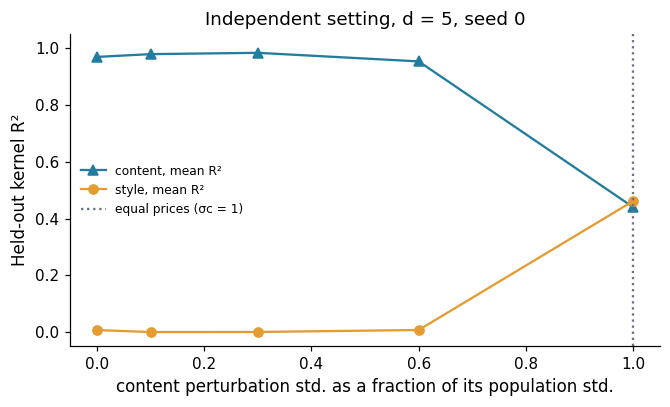

,sigma_c,price_content,price_style,content_nonlinear,style_nonlinear
0,0.0,0.00,1.0,0.9698,0.0068
1,0.1,0.01,1.0,0.9796,-0.0001
2,0.3,0.09,1.0,0.9842,0.0002
3,0.6,0.36,1.0,0.9540,0.0071
4,1.0,1.00,1.0,0.4401,0.4617


At equal prices the benchmark permits different tied subspaces; it does not require block R² = 0.5.
Saved revised outputs to: /content/extension_perturbed_content_v2


In [12]:
# CHANGED [6]: preserve the original independent, one-seed sweep; explicitly distinguish the tie.
if COMPETITION_SIGMAS:
    comp = pd.DataFrame([run_leaky('independent_all', 1.0, False, False, sigma_c,
                                 CONTENT_CHANGE_PROB, SEEDS[0])
                         for sigma_c in COMPETITION_SIGMAS])
    comp['price_content'] = CONTENT_CHANGE_PROB * comp.sigma_c**2
    comp['price_style'] = comp['price_exact_s1']
    comp[[c for c in comp.columns if not c.startswith('_')]].to_csv(
        EXT2_DIR / 'competition_sweep.csv', index=False)
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.plot(comp.sigma_c, comp.content_nonlinear, marker='^', color='#227c9d', label='content, mean R²')
    ax.plot(comp.sigma_c, comp.style_nonlinear, marker='o', color='#e49b32', label='style, mean R²')
    sigma_tie = np.sqrt(float(comp.price_style.iloc[0]) / CONTENT_CHANGE_PROB)
    if min(COMPETITION_SIGMAS) <= sigma_tie <= max(COMPETITION_SIGMAS):
        ax.axvline(sigma_tie, color='#6b7280', linestyle=':', label=f'equal prices (σc = {sigma_tie:g})')
    ax.set(xlabel='content perturbation std. as a fraction of its population std.',
           ylabel='Held-out kernel R²', ylim=(-0.05, 1.05),
           title=f'Independent setting, d = {NC}, seed {SEEDS[0]}')
    ax.legend(frameon=False, fontsize=8)
    fig.tight_layout()
    fig.savefig(EXT2_DIR / 'competition_sweep.png', dpi=150)
    plt.show()
    display(comp[['sigma_c', 'price_content', 'price_style', 'content_nonlinear', 'style_nonlinear']].round(4))
    print('At equal prices the benchmark permits different tied subspaces; it does not require block R² = 0.5.')
else:
    print('Optional independent strength sweep skipped.')
print('Saved revised outputs to:', EXT2_DIR.resolve())

## Historical reference results

The following static tables record the earlier perturbed-only comparison and independent single-seed sweep. They are retained for provenance and are not recomputed by Run All. The paired table above is the source for the report's main Experiment 2 comparison. The historical labels “leaky” and `r_c` denote perturbed original content and its coordinate price, respectively.


### Archived numerical summaries

#### Seed-0 sampled coordinate prices

| Scenario | c1 | c2 | c3 | c4 | c5 | s1 | s2 | s3 | s4 | s5 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_all | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | 0.997 | 1.004 | 1.016 | 0.997 | 1.009 |
| independent_partial | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | 0.752 | 0.744 | 0.758 | 0.744 | 0.762 |
| dependent_blocks | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | 1.813 | 0.944 | 0.838 | 1.279 | 2.233 |
| content_causes_style | 0.01 | 0.01 | 0.01 | 0.01 | 0.01 | 0.228 | 0.176 | 0.317 | 0.422 | 0.842 |

#### Earlier perturbed-only recovery comparison

| Scenario | p(chg.) | Stat. | Cau. | Content c (leaky) | Style s (leaky) | Content c (paper) | Style s (paper) | seeds |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_all | 1.00 | ✗ | ✗ | 0.98 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 0.07 ± 0.00 | 3 |
| independent_partial | 0.75 | ✗ | ✗ | 0.98 ± 0.00 | 0.00 ± 0.00 | 1.00 ± 0.00 | 0.06 ± 0.05 | 3 |
| dependent_blocks | 0.75 | ✓ | ✗ | 0.92 ± 0.04 | 0.57 ± 0.30 | 0.98 ± 0.03 | 0.37 ± 0.05 | 3 |
| content_causes_style | 0.75 | ✓ | ✓ | 0.92 ± 0.03 | 0.88 ± 0.06 | 0.99 ± 0.01 | 0.80 ± 0.08 | 3 |

#### Earlier per-coordinate mean recovery

| Scenario | c1 | c2 | c3 | c4 | c5 | s1 | s2 | s3 | s4 | s5 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| independent_all | 0.98 | 0.98 | 0.98 | 0.98 | 0.98 | 0.00 | 0.00 | 0.00 | 0.00 | -0.00 |
| independent_partial | 0.98 | 0.98 | 0.98 | 0.98 | 0.98 | 0.00 | -0.00 | 0.00 | -0.00 | -0.00 |
| dependent_blocks | 0.93 | 0.85 | 0.95 | 0.96 | 0.90 | 0.55 | 0.29 | 0.60 | 0.57 | 0.84 |
| content_causes_style | 0.96 | 0.85 | 0.94 | 0.97 | 0.87 | 0.95 | 0.78 | 0.94 | 0.85 | 0.88 |

#### Earlier independent single-seed sweep

| Row | sigma_c | r_c | content_nonlinear | style_nonlinear |
| --- | --- | --- | --- | --- |
| 0 | 0.0 | 0.00 | 0.970 | 0.007 |
| 1 | 0.1 | 0.01 | 0.980 | -0.000 |
| 2 | 0.3 | 0.09 | 0.984 | 0.000 |
| 3 | 0.6 | 0.36 | 0.954 | 0.007 |
| 4 | 1.0 | 1.00 | 0.440 | 0.462 |

### References

- von Kügelgen et al. (2021). *Self-Supervised Learning with Data Augmentations Provably Isolates Content from Style*. NeurIPS. [Paper](https://arxiv.org/abs/2106.04619). The paper supplies the four Gaussian settings and the contextual recovery values.
- [Released simulation implementation](https://github.com/ysharma1126/ssl_identifiability/tree/ee46a35acf68461172b3eaeeb1d6fbc779fce661), commit `ee46a35acf68461172b3eaeeb1d6fbc779fce661`, particularly `main_mlp.py`, `spaces.py` and `losses.py`. The present content-perturbation experiments extend that simulation design.
